# Planetary Defense Analytics — 01: Data Understanding, Cleaning & EDA

**Dataset:** NASA JPL Small-Body Database export (958,524 rows × 45 columns)  
**Goal of this notebook:** understand the data, clean it, explore it visually, and save a cleaned file for the modeling notebooks (Case 1, 2, 3).

## 1. Load Data

In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 60)

df = pd.read_csv("../data/dataset.csv", low_memory=False)
print("Shape:", df.shape)
df.head()

Shape: (958524, 45)


,id,spkid,full_name,pdes,name,prefix,neo,pha,H,diameter,albedo,diameter_sigma,orbit_id,epoch,epoch_mjd,epoch_cal,equinox,e,a,q,i,om,w,ma,ad,n,tp,tp_cal,per,per_y,moid,moid_ld,sigma_e,sigma_a,sigma_q,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_tp,sigma_per,class,rms
0,a0000001,2000001,1 Ceres,1,Ceres,NaN,N,N,3.40,939.400,0.0900,0.200,JPL 47,2458600.5,58600,20190427.0,J2000,0.076009,2.769165,2.558684,10.594067,80.305531,73.597695,77.372098,2.979647,0.213885,2.458239e+06,2.018043e+07,1683.145703,4.608202,1.59478,620.640533,4.819000e-12,1.032800e-11,1.956900e-11,4.608900e-09,6.168800e-08,6.624800e-08,7.820700e-09,1.111300e-11,1.196500e-12,3.782900e-08,9.415900e-09,MBA,0.43301
1,a0000002,2000002,2 Pallas,2,Pallas,NaN,N,N,4.20,545.000,0.1010,18.000,JPL 37,2459000.5,59000,20200531.0,J2000,0.229972,2.773841,2.135935,34.832932,173.024741,310.202392,144.975675,3.411748,0.213345,2.458321e+06,2.018072e+07,1687.410992,4.619880,1.23429,480.348639,3.193400e-08,4.033700e-09,8.832200e-08,3.469400e-06,6.272400e-06,9.128200e-06,8.859100e-06,4.961300e-09,4.653600e-10,4.078700e-05,3.680700e-06,MBA,0.35936
2,a0000003,2000003,3 Juno,3,Juno,NaN,N,N,5.33,246.596,0.2140,10.594,JPL 112,2459000.5,59000,20200531.0,J2000,0.256936,2.668285,1.982706,12.991043,169.851482,248.066193,125.435355,3.353865,0.226129,2.458446e+06,2.018112e+07,1592.013769,4.358696,1.03429,402.514639,3.052000e-08,3.471800e-09,8.139200e-08,3.223100e-06,1.664600e-05,1.772100e-05,8.110400e-06,4.363900e-09,4.413400e-10,3.528800e-05,3.107200e-06,MBA,0.33848
3,a0000004,2000004,4 Vesta,4,Vesta,NaN,N,N,3.00,525.400,0.4228,0.200,JPL 35,2458600.5,58600,20190427.0,J2000,0.088721,2.361418,2.151909,7.141771,103.810804,150.728541,95.861938,2.570926,0.271609,2.458248e+06,2.018051e+07,1325.432763,3.628837,1.13948,443.451432,2.332100e-10,1.514300e-09,1.928600e-09,2.170600e-07,3.880800e-07,1.789300e-07,1.206800e-06,1.648600e-09,2.612500e-10,4.103700e-06,1.274900e-06,MBA,0.39980
4,a0000005,2000005,5 Astraea,5,Astraea,NaN,N,N,6.90,106.699,0.2740,3.140,JPL 114,2459000.5,59000,20200531.0,J2000,0.190913,2.574037,2.082619,5.367427,141.571026,358.648418,17.846343,3.065455,0.238661,2.458926e+06,2.020032e+07,1508.414421,4.129814,1.09575,426.433027,2.373700e-08,3.970900e-09,6.092400e-08,2.740800e-06,2.894900e-05,2.984200e-05,8.303800e-06,4.729000e-09,5.522700e-10,3.474300e-05,3.490500e-06,MBA,0.52191


## 2. Data Understanding

### 2.1 Column types

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 958524 entries, 0 to 958523
Data columns (total 45 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   id              958524 non-null  str    
 1   spkid           958524 non-null  int64  
 2   full_name       958524 non-null  str    
 3   pdes            958524 non-null  str    
 4   name            22064 non-null   str    
 5   prefix          18 non-null      str    
 6   neo             958520 non-null  str    
 7   pha             938603 non-null  str    
 8   H               952261 non-null  float64
 9   diameter        136209 non-null  float64
 10  albedo          135103 non-null  float64
 11  diameter_sigma  136081 non-null  float64
 12  orbit_id        958524 non-null  str    
 13  epoch           958524 non-null  float64
 14  epoch_mjd       958524 non-null  int64  
 15  epoch_cal       958524 non-null  float64
 16  equinox         958524 non-null  str    
 17  e               95852

### 2.2 Missing values (%)

In [3]:
missing = (df.isnull().mean() * 100).round(2).sort_values(ascending=False)
missing[missing > 0]

prefix            100.00
name               97.70
albedo             85.91
diameter_sigma     85.80
diameter           85.79
sigma_ma            2.08
sigma_e             2.08
sigma_a             2.08
sigma_q             2.08
sigma_i             2.08
sigma_om            2.08
sigma_w             2.08
sigma_ad            2.08
sigma_n             2.08
moid                2.08
pha                 2.08
sigma_tp            2.08
sigma_per           2.08
H                   0.65
moid_ld             0.01
dtype: float64

**Observations**
- `prefix` (100%) and `name` (97.7%) are almost fully empty → drop.
- `diameter`, `albedo`, `diameter_sigma` are ~86% missing → `diameter` is the Case 2 target, so Case 2 trains only on rows where it exists. `diameter_sigma` is the uncertainty of the target → leakage → drop.
- `pha`, `moid` and all `sigma_*` columns are each missing 2.08% (checked below).
- `H` is missing 0.65% → drop those rows (key predictor).

### 2.3 Target and label distribution

In [4]:
print(df['pha'].value_counts(dropna=False), "\n")
print(df['neo'].value_counts(dropna=False), "\n")
print(df['class'].value_counts())

pha
N      936537
NaN     19921
Y        2066
Name: count, dtype: int64 

neo
N      935625
Y       22895
NaN         4
Name: count, dtype: int64 

class
MBA    855954
OMB     28355
IMB     20360
MCA     18685
APO     12687
AMO      8457
TJN      8221
TNO      3468
ATE      1729
CEN       506
AST        76
IEO        22
HYA         4
Name: count, dtype: int64


**Observations**
- PHA = Y is only **2,066 of 938,603 labelled rows (~0.22%)** → severe class imbalance (~1 : 453).
- A model predicting "N" for everything would score ~99.8% accuracy while catching zero hazards → use **Recall, Precision, F1, PR-AUC**, not accuracy.
- `neo` and `class` encode PHA-adjacent information (every PHA is a NEO; PHAs only come from APO/ATE/AMO/IEO classes) → **excluded from Case 1 features**. `class` is kept only to interpret clusters in Case 3.

### 2.4 Summary statistics

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
spkid,958524.0,3.810114e+06,6.831541e+06,2.000001e+06,2.239632e+06,2.479262e+06,3.752518e+06,5.401723e+07
H,952261.0,1.690641e+01,1.790405e+00,-1.100000e+00,1.610000e+01,1.690000e+01,1.771400e+01,3.320000e+01
diameter,136209.0,5.506429e+00,9.425164e+00,2.500000e-03,2.780000e+00,3.972000e+00,5.765000e+00,9.394000e+02
albedo,135103.0,1.306272e-01,1.103228e-01,1.000000e-03,5.300000e-02,7.900000e-02,1.900000e-01,1.000000e+00
diameter_sigma,136081.0,4.791844e-01,7.828952e-01,5.000000e-04,1.800000e-01,3.320000e-01,6.200000e-01,1.400000e+02
epoch,958524.0,2.458869e+06,7.016716e+02,2.425052e+06,2.459000e+06,2.459000e+06,2.459000e+06,2.459000e+06
epoch_mjd,958524.0,5.886878e+04,7.016716e+02,2.505100e+04,5.900000e+04,5.900000e+04,5.900000e+04,5.900000e+04
epoch_cal,958524.0,2.019693e+07,1.930354e+04,1.927062e+07,2.020053e+07,2.020053e+07,2.020053e+07,2.020053e+07
e,958524.0,1.561163e-01,9.264264e-02,0.000000e+00,9.219296e-02,1.450017e-01,2.006503e-01,1.855356e+00
a,958524.0,2.902143e+00,3.971950e+01,-1.470245e+04,2.387835e+00,2.646969e+00,3.001932e+00,3.348890e+04


### 2.5 Duplicates

In [6]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate ids :", df['id'].duplicated().sum())

Duplicate rows: 0
Duplicate ids : 0


### 2.6 Do the 2.08% missing rows overlap?

In [7]:
print("pha null        :", df['pha'].isnull().sum())
print("moid null       :", df['moid'].isnull().sum())
print("pha & moid null :", (df['pha'].isnull() & df['moid'].isnull()).sum())
print("pha & sigma_e   :", (df['pha'].isnull() & df['sigma_e'].isnull()).sum())

pha null        : 19921
moid null       : 19921
pha & moid null : 19921
pha & sigma_e   : 19921


**Observation:** the same 19,921 rows are missing `pha`, `moid` and all `sigma_*` columns. Dropping them (2.08% of data) removes all three gaps without any imputation.

## 3. Data Cleaning

In [8]:
# 3.1 Drop unused columns
drop_cols = [
    'prefix', 'name',                                   # almost fully empty
    'id', 'spkid', 'full_name', 'pdes', 'orbit_id',     # identifiers
    'diameter_sigma',                                   # uncertainty of target -> leakage
    'equinox',                                          # constant value (J2000)
    'epoch', 'epoch_mjd', 'epoch_cal', 'tp', 'tp_cal'   # date/time stamps, not physical properties
]
df_clean = df.drop(columns=drop_cols)
print("1. After dropping columns      :", df_clean.shape)

# 3.2 Drop rows with no target or missing H
df_clean = df_clean.dropna(subset=['pha', 'H'])
print("2. After dropping pha/H nulls  :", df_clean.shape)

# 3.3 Remove duplicates
before = len(df_clean)
df_clean = df_clean.drop_duplicates()
print("3. Duplicates removed          :", before - len(df_clean))

# 3.4 Remove physically invalid values
before = len(df_clean)
valid = (
    (df_clean['e'] >= 0) & (df_clean['e'] < 1) &        # closed (elliptical) orbit
    (df_clean['a'] > 0) &                                # positive distance
    (df_clean['i'].between(0, 180)) &                    # valid inclination
    (df_clean['diameter'].isna() | (df_clean['diameter'] > 0)) &
    (df_clean['albedo'].isna() | df_clean['albedo'].between(0, 1))
)
df_clean = df_clean[valid]
print("4. Invalid rows removed        :", before - len(df_clean))

# 3.5 Encode Y/N flags as 1/0
df_clean['pha'] = df_clean['pha'].map({'Y': 1, 'N': 0})
df_clean['neo'] = df_clean['neo'].map({'Y': 1, 'N': 0})
print("5. PHA counts:\n", df_clean['pha'].value_counts())

# 3.6 Save cleaned data
df_clean.to_parquet("../data/cleaned.parquet", index=False)
print("6. Saved. Final shape          :", df_clean.shape)

1. After dropping columns      : (958524, 31)
2. After dropping pha/H nulls  : (932341, 31)
3. Duplicates removed          : 0
4. Invalid rows removed        : 4
5. PHA counts:
 pha
0    930271
1      2066
Name: count, dtype: int64
6. Saved. Final shape          : (932337, 31)


**Note:** `moid`, `moid_ld`, `q`, `ad`, `neo` and `class` are kept in the cleaned file on purpose. They are removed per case later (leakage in Case 1), because Case 3 uses `moid_ld` and `class`.

## 4. Exploratory Data Analysis

In [9]:
sample = df_clean.sample(50000, random_state=42)   # sample for faster plotting

### 4.1 Univariate — numeric distributions

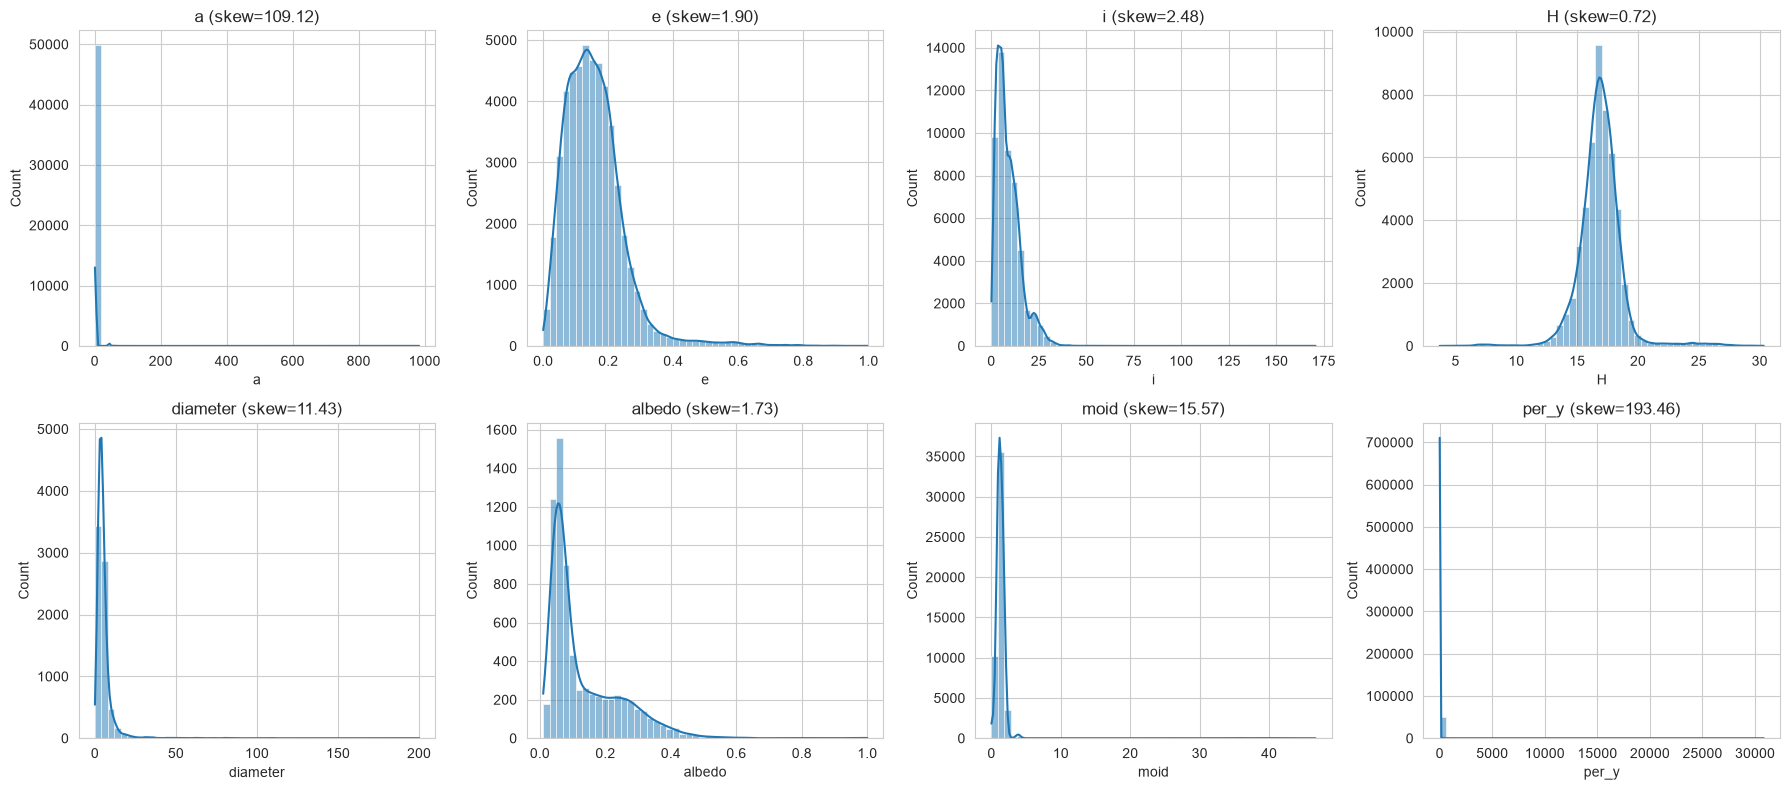

In [10]:
num_cols = ['a', 'e', 'i', 'H', 'diameter', 'albedo', 'moid', 'per_y']
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(sample[col].dropna(), bins=50, kde=True, ax=ax)
    ax.set_title(f"{col} (skew={sample[col].skew():.2f})")
plt.tight_layout(); plt.show()

**Observations:** `a`, `diameter`, `per_y` and `moid` are heavily right-skewed (a few very distant / very large objects) → log transform in preprocessing. These extremes are genuine objects (e.g., TNOs, large asteroids like Ceres), not data errors.

### 4.2 Univariate — categorical flags

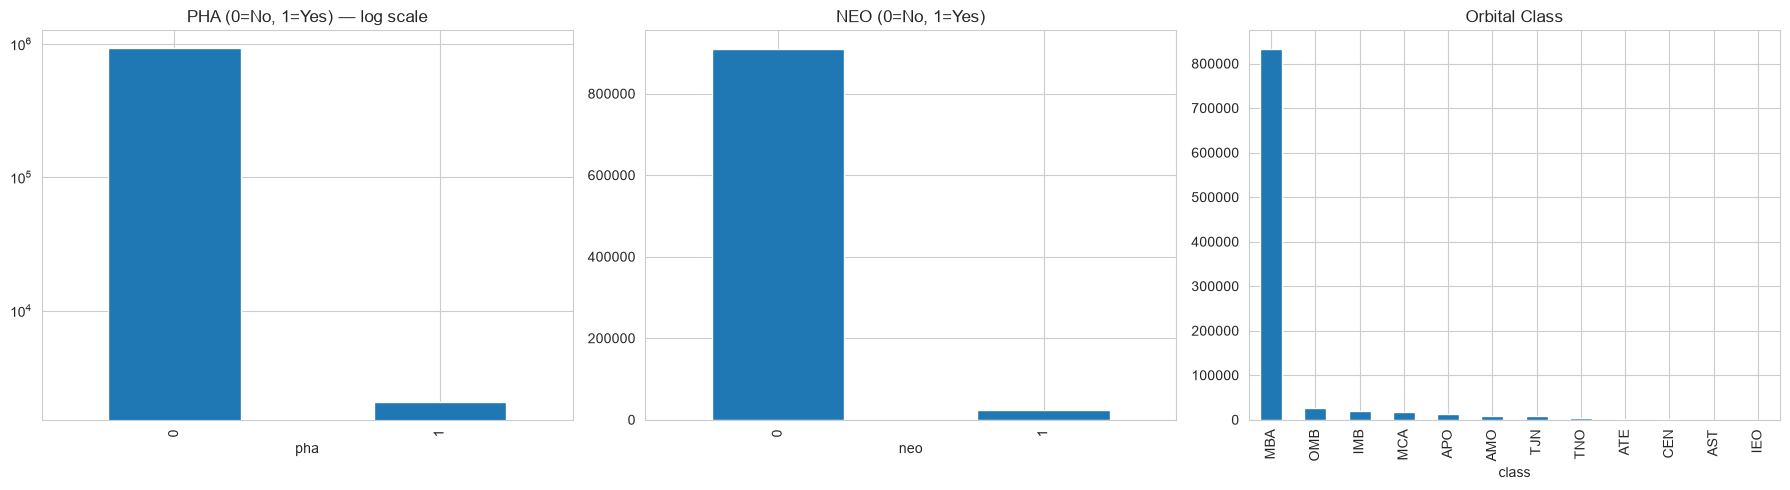

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
df_clean['pha'].value_counts().plot(kind='bar', ax=axes[0], title='PHA (0=No, 1=Yes) — log scale')
df_clean['neo'].value_counts().plot(kind='bar', ax=axes[1], title='NEO (0=No, 1=Yes)')
df_clean['class'].value_counts().plot(kind='bar', ax=axes[2], title='Orbital Class')
axes[0].set_yscale('log')
plt.tight_layout(); plt.show()

**Observations:** extreme PHA imbalance; MBA (Main Belt) dominates the class distribution (~89%).

### 4.3 Bivariate — features vs PHA

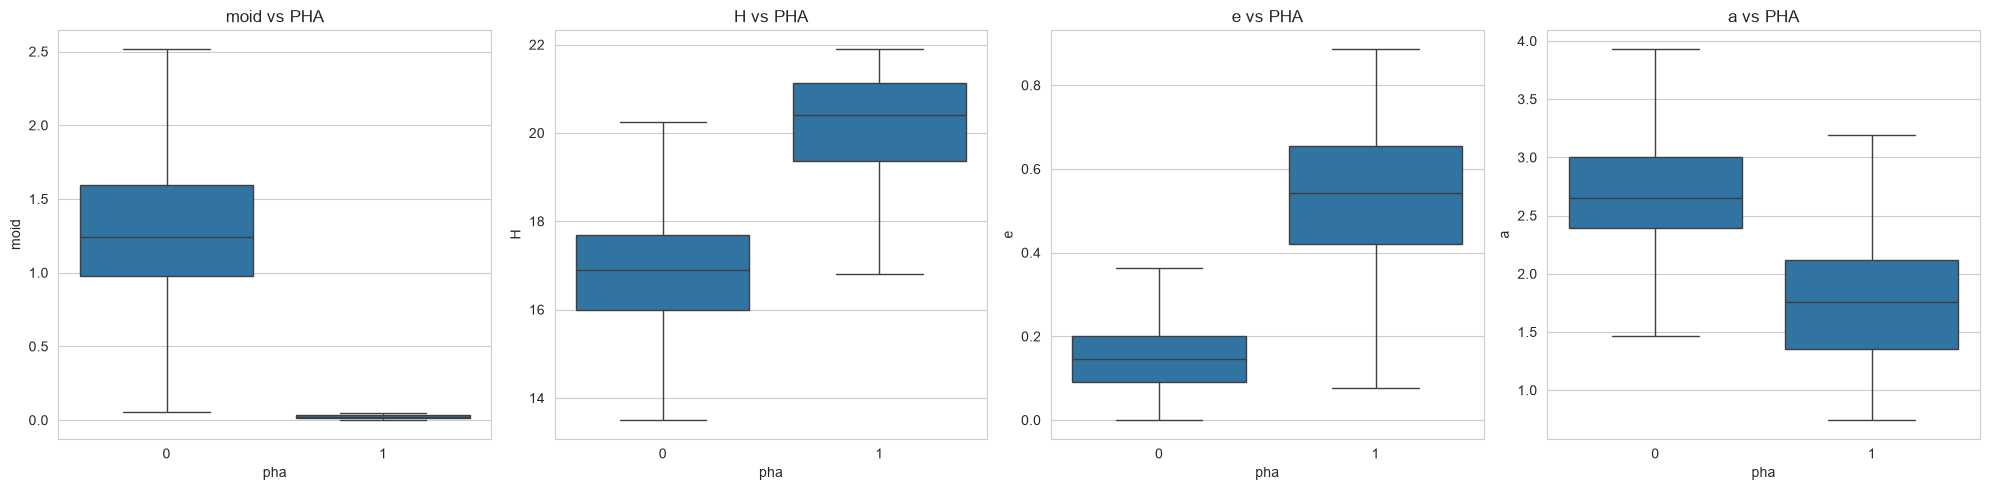

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, col in zip(axes, ['moid', 'H', 'e', 'a']):
    sns.boxplot(data=sample, x='pha', y=col, ax=ax, showfliers=False)
    ax.set_title(f"{col} vs PHA")
plt.tight_layout(); plt.show()

**Observations:** PHAs have near-zero `moid` — because PHA is *defined* as MOID ≤ 0.05 AU and H ≤ 22. Using `moid` would let the model learn the definition rule → **leakage, excluded from Case 1**. `e` is higher and `a` is lower for PHAs → genuine predictive signal.

### 4.4 Bivariate — H vs diameter (Case 2 signal)

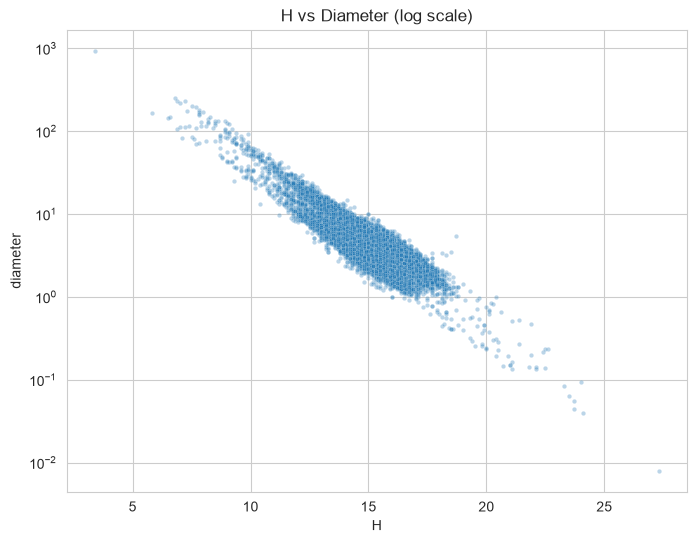

In [13]:
d = df_clean.dropna(subset=['diameter']).sample(20000, random_state=42)
plt.figure(figsize=(8, 6))
sns.scatterplot(data=d, x='H', y='diameter', alpha=0.3, s=10)
plt.yscale('log'); plt.title("H vs Diameter (log scale)"); plt.show()

**Observation:** strong curved (log-linear) relationship — brighter objects (lower H) are larger. Physics: D = 1329 / √albedo × 10^(−H/5). So `log(diameter)` is near-linear in `H` and `log(albedo)` → Case 2 will predict `log10(diameter)`.

### 4.5 Correlation heatmap

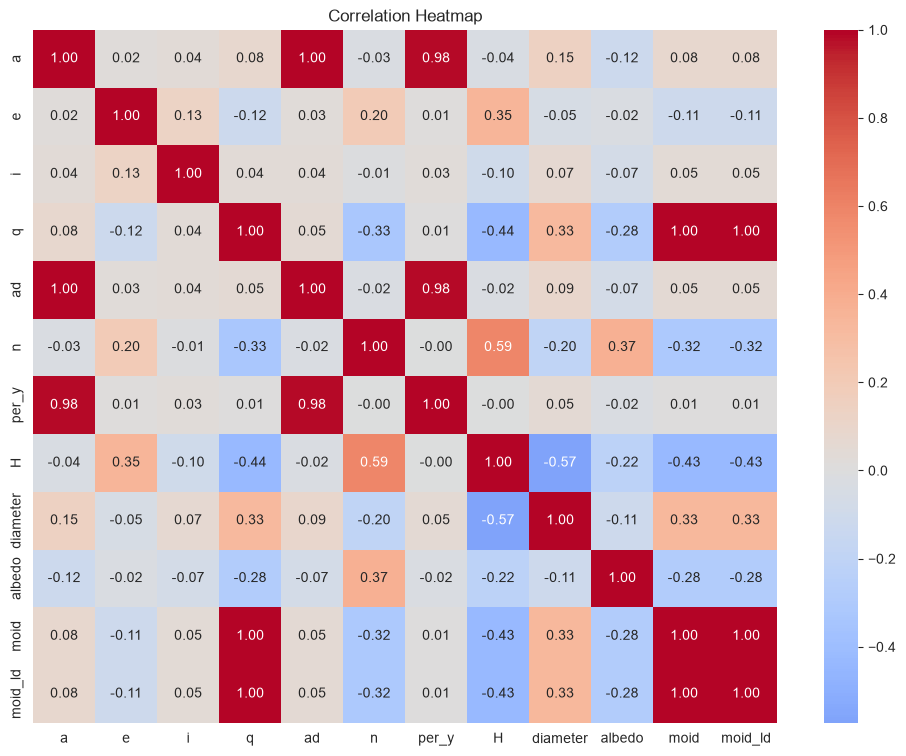

In [14]:
corr_cols = ['a','e','i','q','ad','n','per_y','H','diameter','albedo','moid','moid_ld']
plt.figure(figsize=(12, 9))
sns.heatmap(df_clean[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap"); plt.show()

**Observations**
- `moid` ↔ `moid_ld` = 1.00 → same value in different units (keep one).
- `q` is a near-duplicate of `moid`; `ad = a(1+e)` leaks `q` → both excluded from Case 1.
- `a`, `ad`, `per_y`, `n` are derived from each other → multicollinearity, handled in feature selection.

## 5. Summary
- Cleaned data saved to `data/cleaned.parquet`.
- Leakage columns identified for Case 1: `moid`, `moid_ld`, `q`, `ad`, `neo`, `class`.
- Skewed features flagged for log transform: `a`, `diameter`, `per_y`, `moid`.
- Next notebook: `02_classification.ipynb` (feature selection + Case 1).